# Attribution visualization

**Business context:** stakeholders rarely accept raw attribution vectors. Coloured words, sorted bars and marked-up audio make Shapley and Banzhaf results legible in compliance reviews and product postmortems.

**Goal:** explain three inputs with a real model and show every built-in view: a single prompt (words as players), a multi-speaker conversation (messages as players) and a spoken sentence (words of the audio as players).

**Prerequisites:** `uv sync --extra viz --extra transformers --extra audio`. The first run downloads `Qwen/Qwen2.5-1.5B-Instruct` (3.1 GB) and `facebook/wav2vec2-base-960h` (0.36 GB); a GPU or Apple MPS keeps it to a few minutes.

**Expected output:** attributions of both signs and different sizes, rendered as coloured text, bar charts, HTML and an audio figure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar

from mllm_shap import (
    AudioPart,
    CoalitionMask,
    ConversationSnapshot,
    DeletePolicy,
    ExplainConfig,
    ExplainRunner,
    Message,
    Role,
    TextPart,
    TokenBarRenderer,
    TokenTextRenderer,
    TransformersTextBackend,
    Turn,
    display_attribution_html,
    render_attribution,
    render_attribution_html,
)
from mllm_shap.plugins.context import PluginContext
from mllm_shap.viz import plot_audio_segments, plot_conversation, render_conversation_html

# Progress bars render as widgets that plain viewers (VS Code, GitHub) cannot show.
disable_progress_bars()
disable_progress_bar()

## One model for three explanations

Each coalition's 4-token answer is scored with `tfidf_cosine` against the answer to the full input, so a player earns credit when it moves the answer toward the original and loses credit when it moves it away. The pinned revision keeps the numbers reproducible, the prefix cache reuses shared prompt prefixes, and one backend is loaded once and passed to every runner.

In [2]:
MODEL = {
    "kind": "transformers",
    "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
    "options": {"revision": "989aa7980e4cf806f80c7fef2b1adb7bc71aa306", "dtype": "float16"},
}


SYSTEM = (
    "You are a support assistant for a store. Answer only from the question, in one "
    'short sentence. If it does not give enough information, say "Not enough '
    'information." Never invent policy details and never ask a question.'
)
ROLES = {"tokens": ["user"], "messages": ["user", "assistant"]}  # the system prompt is no player


def config(**explanation: object) -> ExplainConfig:
    players = explanation.get("players", "tokens")
    roles = {players: {"roles": ROLES[players]}} if players in ROLES else {}
    return ExplainConfig.model_validate({
        "backend": MODEL,
        "generation": {"max_new_tokens": 4},
        "explanation": {
            "value_fn": "tfidf_cosine",
            "absence_policy": "delete",
            "kv_cache": {"enabled": True},
            "archive": {"path": ""},
            "plugin_options": roles,
            **explanation,
        },
    })


backend = TransformersTextBackend(PluginContext(config=config()))

In [3]:
async def answers_without(output, snapshot) -> None:
    """Print the answer to the full input and to the input without each player."""
    generation = config().generation
    answer = await backend.generate(snapshot, generation)
    print(f"{'full input':>28} -> {answer.text!r}")
    players = output.player_set
    for index, span in enumerate(players.spans):
        mask = CoalitionMask.from_sequence(
            tuple(other != index for other in range(players.num_players))
        )
        absent = DeletePolicy().apply(snapshot, players, mask)
        answer = await backend.generate(absent, generation)
        print(f"{'without ' + span.display_label[:20]:>28} -> {answer.text!r}")


def show(output) -> None:
    for span, value in zip(output.player_set.spans, output.result.values, strict=True):
        print(f"{span.display_label[:44]:44} {value:+.3f}")
    print("sum", round(sum(output.result.values), 4), "= grand - base",
          round(output.result.grand_value - output.result.base_value, 4))

## Words of a single prompt

**Business:** a support assistant is asked about a refund for a broken laptop that the customer already opened; reviewers want to see which words drive the answer.

**Technical:** 13 word players, complementary contributions with a budget of 160 evaluations (exact enumeration would need 8192).

In [4]:
prompt = ConversationSnapshot.from_turns((
    Turn(messages=(
        Message(role=Role.SYSTEM, text=SYSTEM),
        Message(
            role=Role.USER,
            text="The laptop arrived broken but I opened it. Refund? Answer yes or no.",
        ),
    )),
))
words = await ExplainRunner(
    config(estimator="complementary", budget={"evaluations": 160}), backend=backend
).explain(prompt)
show(words)

The                                          +0.041
laptop                                       -0.016
arrived                                      +0.081
broken                                       +0.121
but                                          +0.156
I                                            +0.079
opened                                       +0.129
it.                                          +0.115
Refund?                                      -0.086
Answer                                       +0.166
yes                                          +0.174
or                                           -0.082
no.                                          +0.159
sum 1.0367 = grand - base 1.0


In [5]:
await answers_without(words, prompt)

                  full input -> 'Yes.'


                 without The -> 'Yes.'


              without laptop -> 'Yes.'


             without arrived -> 'Not enough information.'


              without broken -> 'Not enough information.'
                 without but -> 'Yes'


                   without I -> 'Yes.'


              without opened -> 'No.'


                 without it. -> 'No.'
             without Refund? -> 'Yes.'


              without Answer -> 'Not enough information.'
                 without yes -> 'Not enough information.'


                  without or -> 'Yes.'
                 without no. -> 'Yes'


The answers above explain the values. Dropping `yes` or `no.` makes the model say "Not enough information." (the largest values, +0.25 each), as does dropping `broken` or `arrived`. Dropping `opened` or `it.` flips the answer to "No.": the opened box is what tips it. The values add up to `grand_value - base_value` up to sampling error.

### Coloured words and bars

`render_attribution` returns a matplotlib figure; pass the run's `player_set` so labels match the players. Red marks positive values, blue negative ones, and the colour intensity follows the size. `token_bar` sorts the players by absolute value.

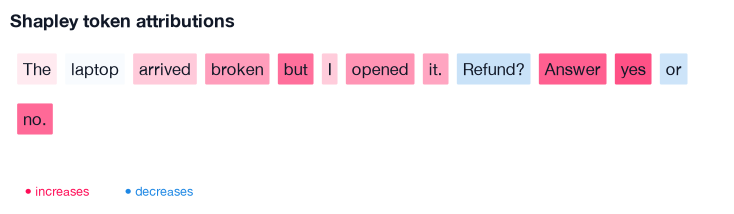

In [6]:
render_attribution(words, prompt, words.player_set, renderer="token_text")
plt.show()

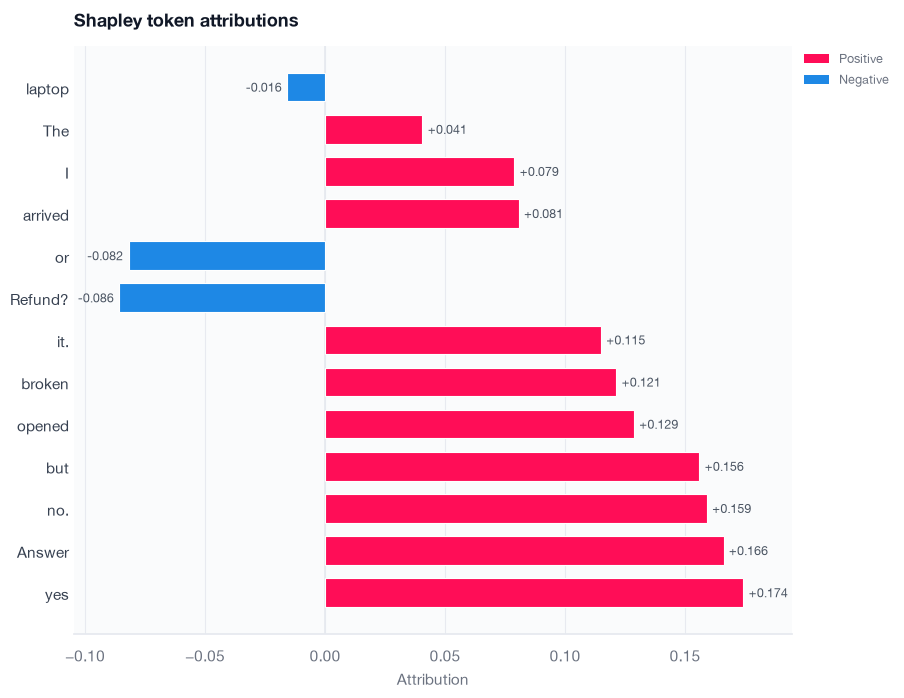

In [7]:
render_attribution(words, prompt, words.player_set, renderer="token_bar")
plt.show()

### HTML

In Jupyter, `display_attribution_html` shows the coloured words without matplotlib; `render_attribution_html` returns the same fragment as a string for reports and emails.

In [8]:
display_attribution_html(words, prompt, words.player_set, title="Refund request")
html = render_attribution_html(words, prompt, words.player_set, title="Refund request")
print(len(html), "characters;", html.count("background-color"), "coloured words")

2328 characters; 13 coloured words


## A multi-speaker conversation

**Business:** in a shared support thread, which message decided the answer, and whose?

**Technical:** `players: messages` makes each message one player, labelled with its role, speaker and position; five players allow exact enumeration (32 coalitions).

In [9]:
thread = ConversationSnapshot.from_turns((
    Turn(messages=(Message(role=Role.SYSTEM, text=SYSTEM),)),
    Turn(messages=(Message(role=Role.USER, speaker="Alice", text="I ordered a laptop on May 2."),)),
    Turn(messages=(Message(role=Role.ASSISTANT, text="Thanks. How can I help?"),)),
    Turn(messages=(Message(role=Role.USER, speaker="Bob", text="It arrived with a cracked screen."),)),
    Turn(messages=(Message(role=Role.USER, speaker="Alice", text="We used it once before we noticed."),)),
    Turn(messages=(Message(role=Role.USER, speaker="Bob", text="Can we get a refund? Answer yes or no."),)),
))
shapley_runner = ExplainRunner(config(estimator="exact", players="messages"), backend=backend)
messages = await shapley_runner.explain(thread)
show(messages)

user/Alice 2: I ordered a laptop on May 2.   +0.250
assistant 3: Thanks. How can I help?         +0.250
user/Bob 4: It arrived with a cracked scre…  +0.250
user/Alice 5: We used it once before we noti +0.000
user/Bob 6: Can we get a refund? Answer ye…  +0.250
sum 1.0 = grand - base 1.0


In [10]:
await answers_without(messages, thread)

                  full input -> 'Yes.'


without user/Alice 2: I orde -> 'No.'


without assistant 3: Thanks. -> 'Not enough information.'


without user/Bob 4: It arriv -> 'Not enough information.'
without user/Alice 5: We use -> 'Yes.'


without user/Bob 6: Can we g -> 'The laptop was returned'


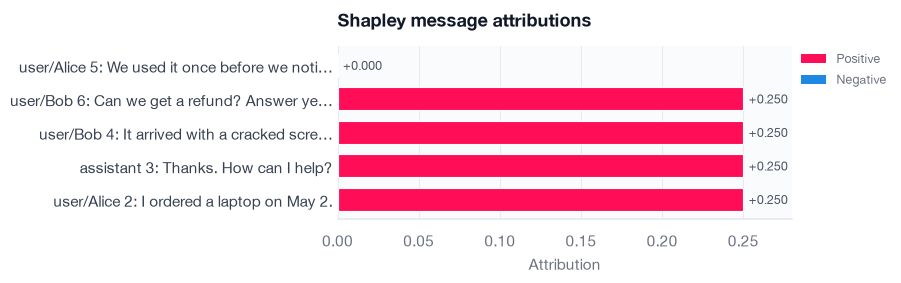

In [11]:
render_attribution(messages, thread, messages.player_set, renderer="token_bar",
                   title="Shapley message attributions")
plt.show()

`plot_conversation` keeps the thread's shape: one block per message under its role, speaker and position, with each player shaded where it stands. `render_conversation_html` returns the same view as HTML; hovering a player shows its value.

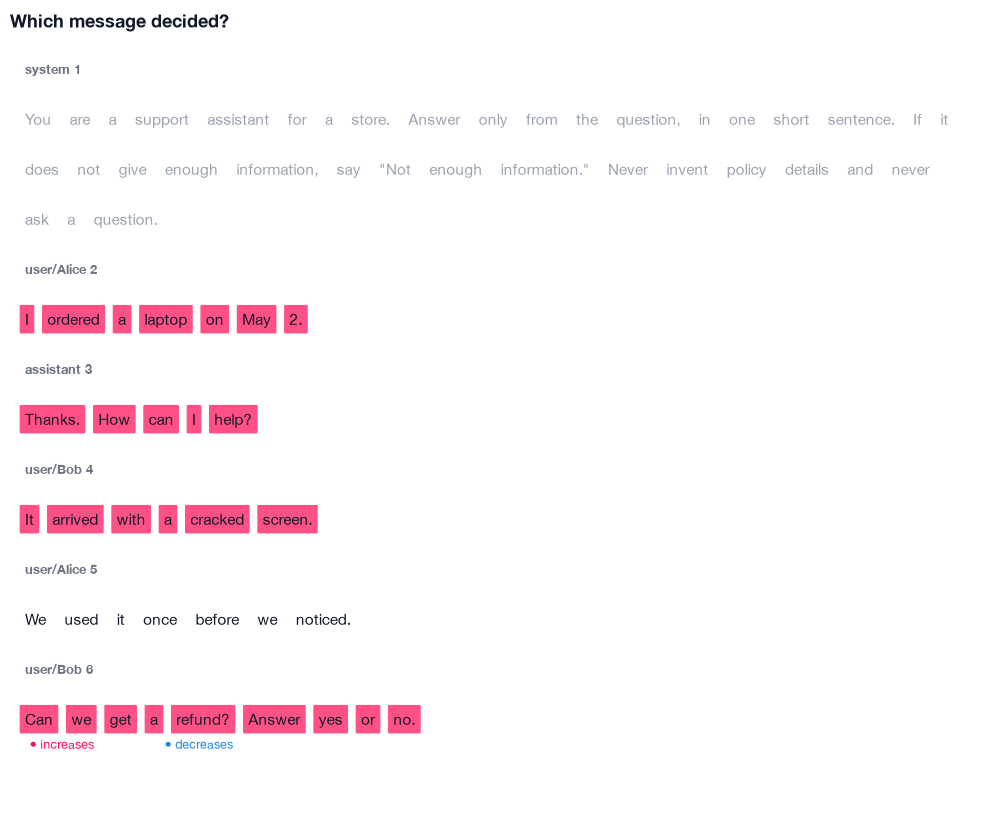

In [12]:
plot_conversation(messages, thread, messages.player_set, title="Which message decided?")
plt.show()

### Words of the users only

**Business:** reviewers care about what the customers wrote; the assistant's and system's text is context, not evidence.

**Technical:** `players: tokens` with `plugin_options: {tokens: {roles: [user]}}` makes only the users' words players; the system prompt and the assistant message stay present in every coalition and appears grey. The same `roles` option filters `players: messages`. 29 word players need a sampled estimator: complementary contributions with 200 evaluations.

In [13]:
user_words = await ExplainRunner(
    config(
        estimator="complementary",
        budget={"evaluations": 200},
        players="tokens",
        plugin_options={"tokens": {"roles": ["user"]}},
    ),
    backend=backend,
).explain(thread)
show(user_words)

Alice: I                                     +0.005
Alice: ordered                               -0.037
Alice: a                                     -0.003
Alice: laptop                                +0.044
Alice: on                                    +0.081
Alice: May                                   +0.001
Alice: 2.                                    -0.028
Bob: It                                      +0.001
Bob: arrived                                 +0.081
Bob: with                                    +0.039
Bob: a                                       +0.006
Bob: cracked                                 +0.117
Bob: screen.                                 +0.044
Alice: We                                    +0.005
Alice: used                                  -0.051
Alice: it                                    +0.038
Alice: once                                  +0.006
Alice: before                                +0.064
Alice: we                                    +0.044
Alice: notic

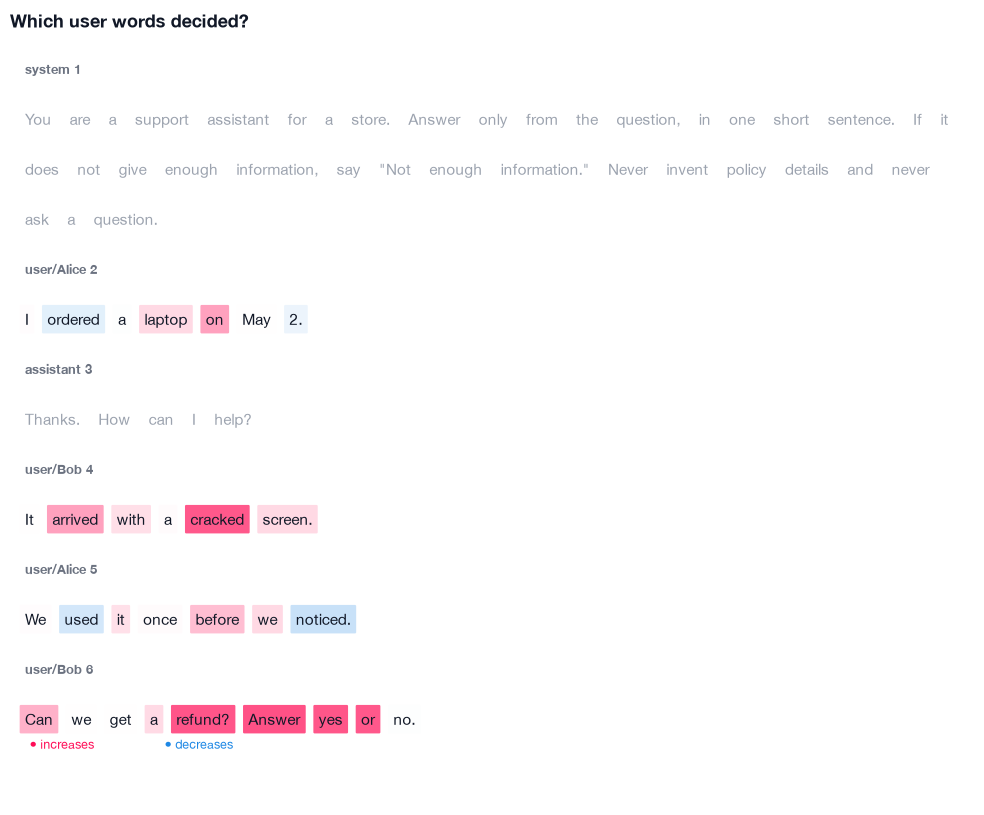

In [14]:
plot_conversation(user_words, thread, user_words.player_set, title="Which user words decided?")
plt.show()

In [15]:
html = render_conversation_html(user_words, thread, user_words.player_set)
print(html.count("mllm-shap-player"), "coloured user words; assistant text kept:", "How can I help?" in html)

29 coloured user words; assistant text kept: True


### Renderer classes and Banzhaf values

`TokenTextRenderer` and `TokenBarRenderer` are the plugin classes behind the renderer names: `render(labels, values, estimand=..., title=...)` draws any labelled vector, and `to_html` returns the HTML fragment. With `registry=runner.registry`, `render_attribution` resolves renderers you registered yourself. Without `title=`, the bar chart names the estimand, so a Banzhaf chart is not mistaken for Shapley values; Banzhaf values need not add up.

to_html matches: True


user/Alice 2: I ordered a laptop on May 2.   +0.125
assistant 3: Thanks. How can I help?         +0.125
user/Bob 4: It arrived with a cracked scre…  +0.125
user/Alice 5: We used it once before we noti +0.000
user/Bob 6: Can we get a refund? Answer ye…  +0.125
sum 0.5 = grand - base 1.0


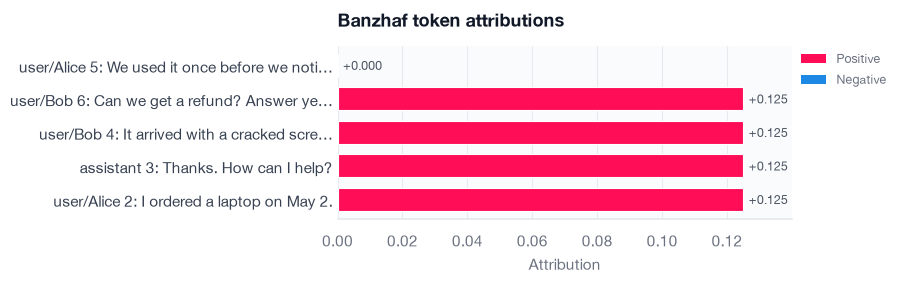

In [16]:
labels = [span.display_label for span in messages.player_set.spans]
print("to_html matches:", TokenTextRenderer().to_html(labels, messages.result.values,
      estimand=messages.result.estimand) == render_attribution_html(messages, thread, messages.player_set))
banzhaf_runner = ExplainRunner(
    config(estimator="exact", estimand="banzhaf", players="messages"), backend=backend
)
banzhaf = await banzhaf_runner.explain(thread)
show(banzhaf)
TokenBarRenderer().render(labels, banzhaf.result.values, estimand=banzhaf.result.estimand)
plt.show()

## Spoken words

**Business:** a voice assistant hears a sentence; which spoken words shaped its reading of the speaker's mood?

**Technical:** `players: sgpa_segments` aligns the recording (`voices_sp0307.wav`, VOiCES corpus, CC BY 4.0) to its transcript and makes each spoken word a player whose audio and text are masked together. No backend generates from audio yet, so a small wrapper hands the model the masked transcript.

In [17]:
class TranscriptReader:
    """Give the text model the masked transcript of each audio message."""

    model_id = backend.model_id

    async def generate(self, snapshot, generation):
        text_only = ConversationSnapshot.from_turns(tuple(
            Turn(messages=tuple(
                Message(role=m.role, text=m.text, speaker=m.speaker) for m in turn.messages
            ))
            for turn in snapshot.turns
        ))
        return await backend.generate(text_only, generation)


clip = AudioPart(Path("voices_sp0307.wav"), sample_rate=16000)
spoken = ConversationSnapshot.from_turns((Turn(messages=(
    Message(role=Role.SYSTEM, text=SYSTEM),
    Message(role=Role.USER, text="How did the speaker feel? Answer in one word."),
    Message(role=Role.USER, content=(TextPart("I had that curiosity beside me at this moment"), clip)),
)),))
audio_config = config(
    estimator="complementary", budget={"evaluations": 128}, players="sgpa_segments",
    plugin_options={"sgpa_segments": {
        "model_id": "facebook/wav2vec2-base-960h",
        "revision": "22aad52d435eb6dbaf354bdad9b0da84ce7d6156",
    }},
)
heard = await ExplainRunner(audio_config, backend=TranscriptReader()).explain(spoken)
show(heard)

I                                            +0.045
had                                          +0.071
that                                         -0.062
curiosity                                    +0.776
beside                                       -0.119
me                                           +0.105
at                                           -0.015
this                                         +0.041
moment                                       +0.204
sum 1.0448 = grand - base 1.0


`plot_audio_segments` draws each word's stretch of audio coloured by its value, over the waveform and its energy; `token_bar` ranks the same players.

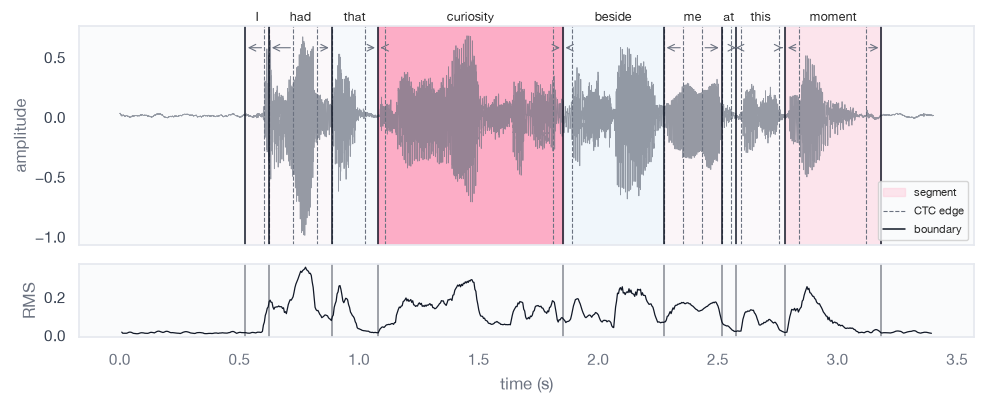

In [18]:
from mllm_shap.alignment import SpectrogramGuidedAligner, Wav2Vec2Ctc

aligner = SpectrogramGuidedAligner(Wav2Vec2Ctc(
    "facebook/wav2vec2-base-960h", revision="22aad52d435eb6dbaf354bdad9b0da84ce7d6156"))
segments = aligner.align("I had that curiosity beside me at this moment", clip)
plot_audio_segments(clip, segments, values=list(heard.result.values))
plt.show()

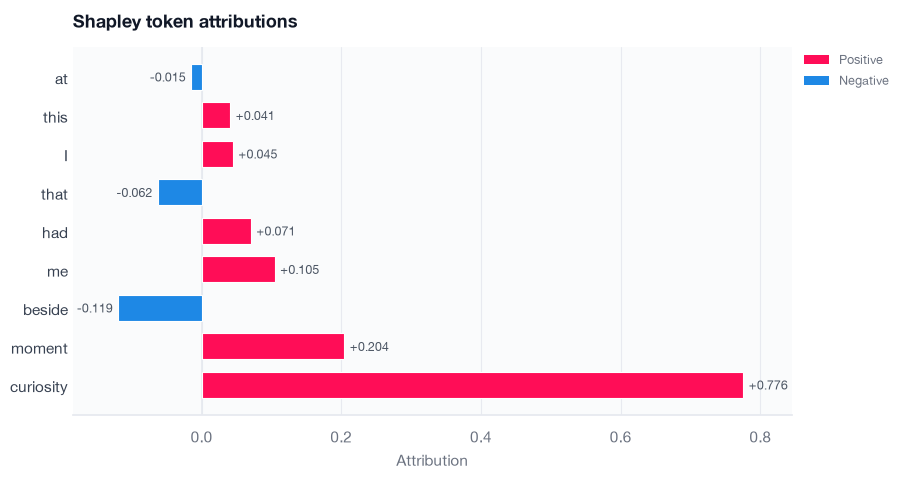

In [19]:
render_attribution(heard, spoken, heard.player_set, renderer="token_bar")
plt.show()

## Typed and spoken words together

**Business:** the question was typed and the answer spoken; which words, of either kind, shaped the reply?

**Technical:** the `sgpa_segments` option `text_roles: [user]` also makes the words of the typed user message players, so both kinds share one run and one colour scale (18 players, complementary contributions with 240 evaluations). `plot_conversation` shows the typed words in place and adds a waveform strip for the spoken message, shaded on the same scale.

How                                          +0.210
did                                          -0.082
the                                          +0.039
speaker                                      +0.025
feel?                                        +0.148
Answer                                       -0.026
in                                           +0.035
one                                          +0.198
word.                                        +0.196
I                                            -0.011
had                                          -0.025
that                                         +0.042
curiosity                                    +0.196
beside                                       +0.010
me                                           -0.090
at                                           +0.041
this                                         +0.023
moment                                       +0.064
sum 0.9906 = grand - base 1.0


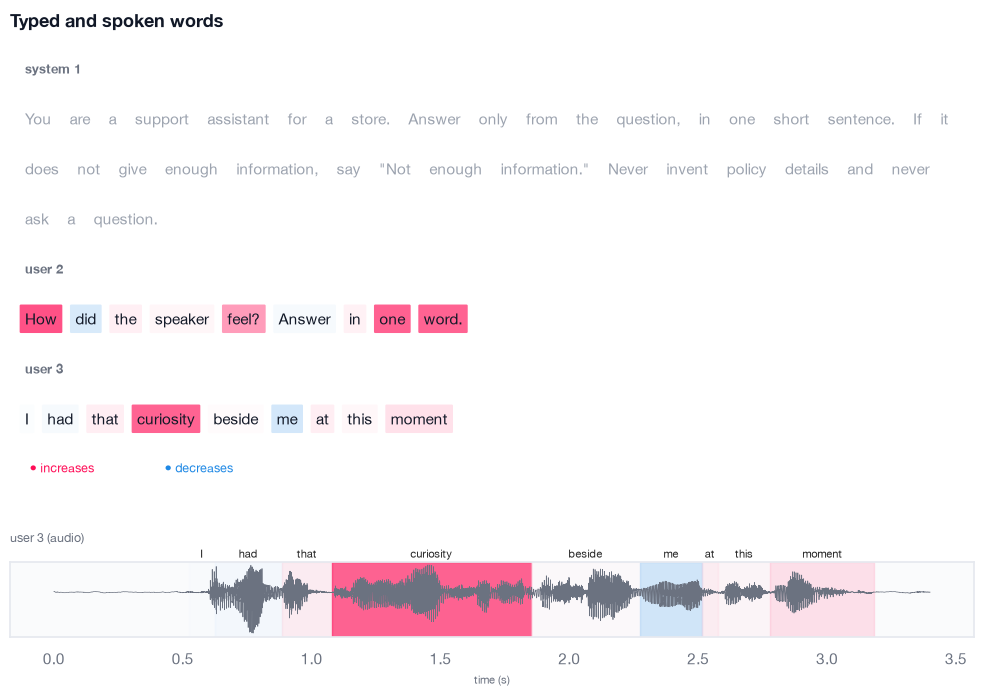

In [20]:
mixed_config = config(
    estimator="complementary", budget={"evaluations": 240}, players="sgpa_segments",
    plugin_options={"sgpa_segments": {
        "model_id": "facebook/wav2vec2-base-960h",
        "revision": "22aad52d435eb6dbaf354bdad9b0da84ce7d6156",
        "text_roles": ["user"],
    }},
)
mixed = await ExplainRunner(mixed_config, backend=TranscriptReader()).explain(spoken)
show(mixed)
plot_conversation(mixed, spoken, mixed.player_set, title="Typed and spoken words")
plt.show()